In [ ]:

def costo_entrada(modelo, token):

    if token < 0:
        raise ValueError("Los Tokens no puede ser negativa")

    if modelo == "astra" and token < 272000 and token:
        return token * 10 / 1000000
    elif modelo == "astra":
        return token * 20 / 1000000

    if modelo == "sol" and token < 272000 and token:
        return token * 2 / 1000000
    elif modelo == "sol":
        return token * 4 / 1000000

    if modelo == "luna" and token < 272000 and token:
        return token * 0.10 / 1000000
    elif modelo == "luna":
        return token * 0.20 / 1000000

    raise ValueError("Modelo no reconocido")


In [23]:
print(costo_entrada("astra",1000000),"dolares")

20.0 dolares


In [ ]:

import matplotlib.pyplot as plt

def graficar_costos(tokens, archivo="costos_api.png"):
    """Dibuja el costo de entrada frente al número de tokens."""

    modelos = ["astra", "sol", "luna"]

    costos_por_modelo = {
        modelo: [costo_entrada(modelo, token) for token in tokens]
        for modelo in modelos
    }

    fig, (lineal, logaritmica) = plt.subplots(
        1, 2, figsize=(12, 4.5)
    )

    for modelo, costos in costos_por_modelo.items():
        lineal.plot(tokens, costos, marker="o", label=modelo)
        logaritmica.plot(tokens, costos, marker="o", label=modelo)

    for ax in (lineal, logaritmica):
        ax.axvline(
            272_000,
            color="gray",
            linestyle="--",
            linewidth=1,
            label="Umbral: 272 000 tokens"
        )
        ax.set_xlabel("Tokens de entrada")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()

    lineal.set_title("Escala lineal")
    lineal.set_ylabel("Costo (USD)")

    logaritmica.set_title("Escala logarítmica")
    logaritmica.set_ylabel("Costo (USD, escala logarítmica)")
    logaritmica.set_yscale("log")

    fig.suptitle("Costo de entrada según el número de tokens")
    fig.tight_layout()

    fig.savefig(archivo, dpi=150)
    plt.show()


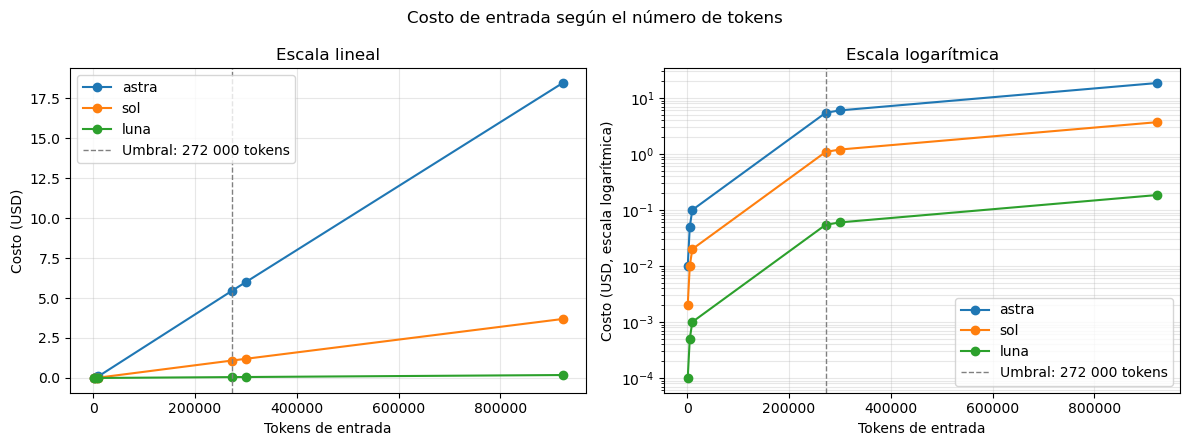

In [25]:

tokens = [1000, 5000, 10000, 272000, 300000, 922000]

graficar_costos(tokens)
